# BCSE331P – Exploratory Data Analysis
## Assessment 6: Time Series Analysis (AirPassengers)
Monthly international airline passengers (thousands), Jan 1949 – Dec 1960.

**Q1. Load the AirPassengers dataset** (built-in in R; embedded here as a monthly time series)

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

values = """112 118 132 129 121 135 148 148 136 119 104 118
115 126 141 135 125 149 170 170 158 133 114 140
145 150 178 163 172 178 199 199 184 162 146 166
171 180 193 181 183 218 230 242 209 191 172 194
196 196 236 235 229 243 264 272 237 211 180 201
204 188 235 227 234 264 302 293 259 229 203 229
242 233 267 269 270 315 364 347 312 274 237 278
284 277 317 313 318 374 413 405 355 306 271 306
315 301 356 348 355 422 465 467 404 347 305 336
340 318 362 348 363 435 491 505 404 359 310 337
360 342 406 396 420 472 548 559 463 407 362 405
417 391 419 461 472 535 622 606 508 461 390 432""".split()
AirPassengers = pd.Series([int(v) for v in values],
                          index=pd.date_range("1949-01", periods=144, freq="MS"), name="AirPassengers")
AirPassengers.head()

,AirPassengers
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


**Q2. First five and last five observations**

In [2]:
print(AirPassengers.head(5)); print(); print(AirPassengers.tail(5))

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: AirPassengers, dtype: int64

1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: AirPassengers, dtype: int64


**Q3. Start and end time periods**

In [3]:
print("Start:", AirPassengers.index[0].strftime("%b %Y")); print("End  :", AirPassengers.index[-1].strftime("%b %Y"))

Start: Jan 1949
End  : Dec 1960


**Q4. Frequency and time-series characteristics**

In [4]:
print("Frequency      :", AirPassengers.index.freqstr, "(monthly -> 12 observations per year)")
print("Class          :", type(AirPassengers).__name__, "with", type(AirPassengers.index).__name__)
print("Observations   :", len(AirPassengers))
AirPassengers.describe()

Frequency      : MS (monthly -> 12 observations per year)
Class          : Series with DatetimeIndex
Observations   : 144


,AirPassengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


**Q5. Monthly passenger trend**

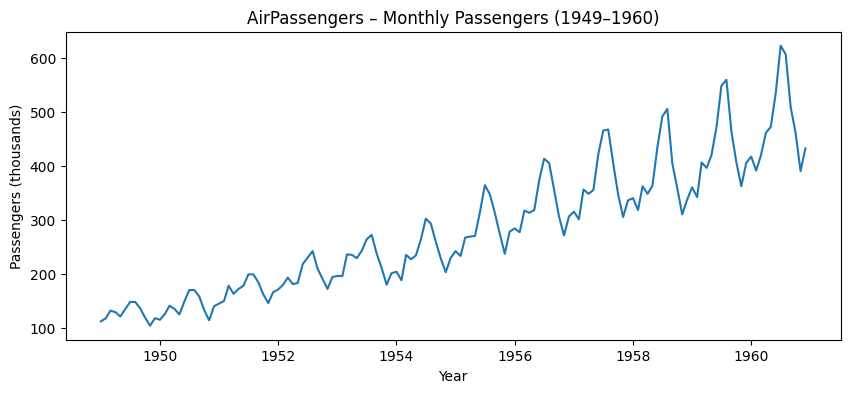

In [5]:
plt.figure(figsize=(10,4)); plt.plot(AirPassengers)
plt.title("AirPassengers – Monthly Passengers (1949–1960)"); plt.xlabel("Year"); plt.ylabel("Passengers (thousands)"); plt.show()

**Q6. Decompose into trend, seasonal and random components**

In [6]:
dec = seasonal_decompose(AirPassengers, model="additive", period=12)
pd.DataFrame({"trend": dec.trend, "seasonal": dec.seasonal, "random": dec.resid}).head(14).round(2)

,trend,seasonal,random
1949-01-01,NaN,-24.75,NaN
1949-02-01,NaN,-36.19,NaN
1949-03-01,NaN,-2.24,NaN
1949-04-01,NaN,-8.04,NaN
1949-05-01,NaN,-4.51,NaN
1949-06-01,NaN,35.40,NaN
1949-07-01,126.79,63.83,-42.62
1949-08-01,127.25,62.82,-42.07
1949-09-01,127.96,16.52,-8.48
1949-10-01,128.58,-20.64,11.06


**Q7. Plot the decomposed components**

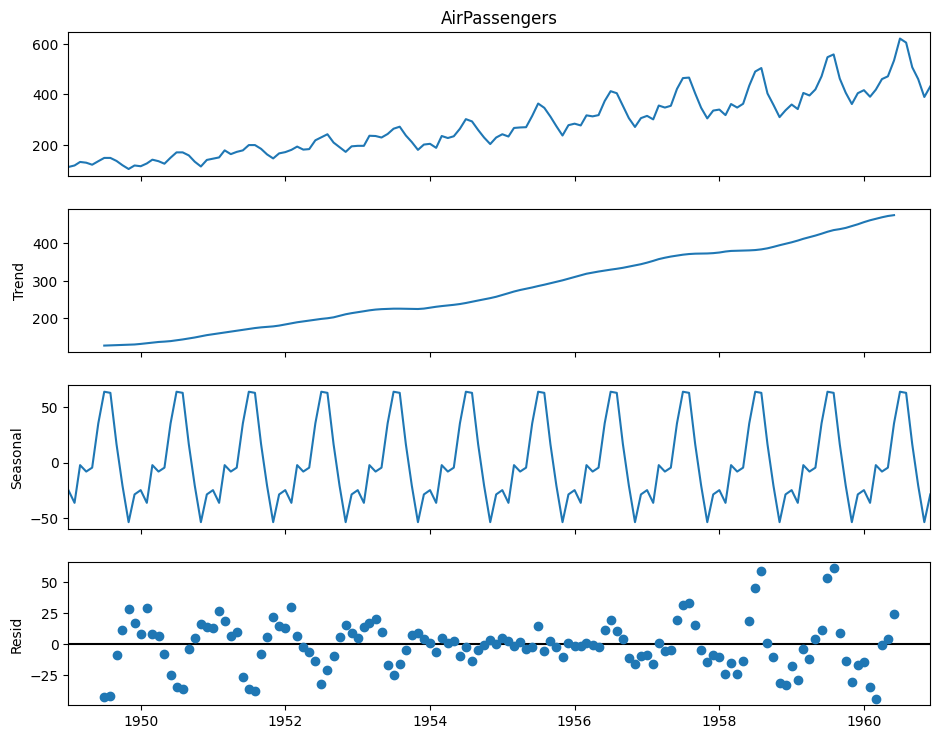

In [7]:
fig = dec.plot(); fig.set_size_inches(10, 8); plt.show()

**Q8. Autocorrelation (ACF) and partial autocorrelation (PACF)**

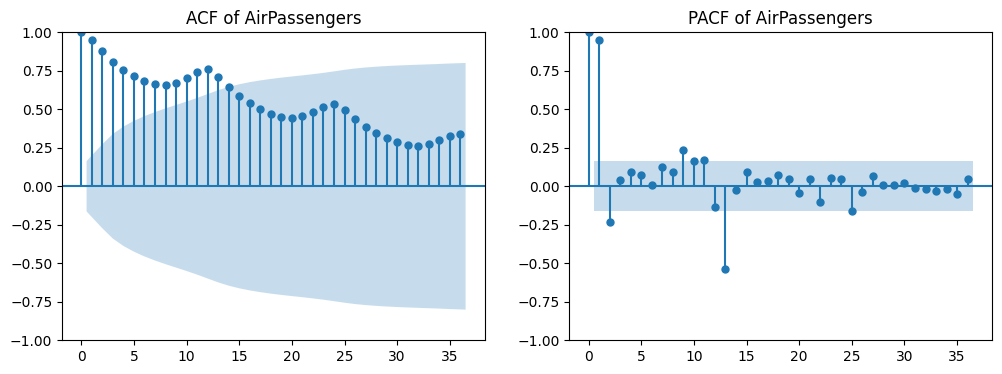

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(AirPassengers, lags=36, ax=ax[0]); ax[0].set_title("ACF of AirPassengers")
plot_pacf(AirPassengers, lags=36, ax=ax[1], method="ywm"); ax[1].set_title("PACF of AirPassengers")
plt.show()

**Q9. Fit an ARIMA model** – ARIMA(0,1,1)(0,1,1)[12] (seasonal differencing handles the yearly cycle)

In [9]:
model = ARIMA(AirPassengers, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
fit = model.fit()

**Q10. Model parameters and summary**

In [10]:
print(fit.summary())
print("\nCoefficients:\n", fit.params.round(4))
print(f"\nAIC = {fit.aic:.2f} | BIC = {fit.bic:.2f}")
print("Interpretation: ma.L1 = non-seasonal MA(1) term, ma.S.L12 = seasonal MA(1) term; negative values mean "
      "a shock is partly corrected in the next month / next year. Lower AIC = better fit.")

                                    SARIMAX Results                                     
Dep. Variable:                    AirPassengers   No. Observations:                  144
Model:             ARIMA(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -507.501
Date:                          Sat, 17 Oct 2026   AIC                           1021.003
Time:                                  15:17:28   BIC                           1029.628
Sample:                              01-01-1949   HQIC                          1024.507
                                   - 12-01-1960                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3087      0.068     -4.507      0.000      -0.443      -0.174
ma.S.L12      -0.1075      0.091     -1.184      0.

**Q11. Forecast the next 12 months**

In [11]:
fc = fit.get_forecast(steps=12)
forecast = fc.predicted_mean; ci = fc.conf_int()
pd.DataFrame({"Forecast": forecast.round(1), "Lower 95%": ci.iloc[:, 0].round(1), "Upper 95%": ci.iloc[:, 1].round(1)})

,Forecast,Lower 95%,Upper 95%
1961-01-01,447.1,424.2,469.9
1961-02-01,421.9,394.1,449.6
1961-03-01,453.5,421.6,485.4
1961-04-01,489.9,454.3,525.5
1961-05-01,502.2,463.3,541.1
1961-06-01,564.2,522.2,606.2
1961-07-01,649.8,604.9,694.7
1961-08-01,636.7,589.2,684.3
1961-09-01,538.9,488.8,589.0
1961-10-01,491.1,438.6,543.6


**Q12. Actual vs forecasted values**

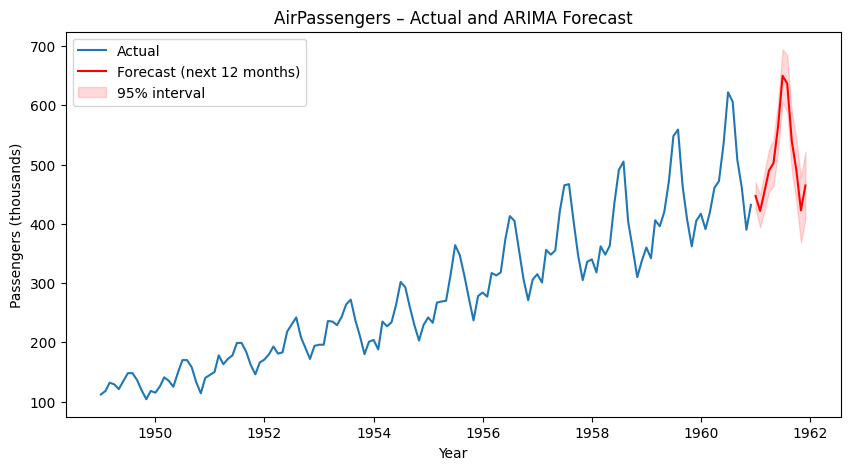

In [12]:
plt.figure(figsize=(10,5))
plt.plot(AirPassengers, label="Actual")
plt.plot(forecast, color="red", label="Forecast (next 12 months)")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="red", alpha=.15, label="95% interval")
plt.title("AirPassengers – Actual and ARIMA Forecast"); plt.xlabel("Year"); plt.ylabel("Passengers (thousands)"); plt.legend(); plt.show()